# 02 — Análise Exploratória (EDA), Cestas e Split 80/20 Anti-Leakage

Cobre a **Etapa 3** (`docs/3_eda.md`) e a **Etapa 4** (`docs/4_dataset_e_split.md`), exibindo os 6 gráficos de evidência, as estatísticas de co-ocorrência e a verificação do split 80/20 + expansão $2^k - 2$.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import EDA_SUMMARY_PATH, FIGURES_DIR, SPLITS_DIR
from src.data.dataset_builder import carregar_splits

with EDA_SUMMARY_PATH.open('r', encoding='utf-8') as fp:
    eda_summary = json.load(fp)
print(json.dumps(eda_summary['cestas_varejo'], indent=2, ensure_ascii=False))
print(json.dumps(eda_summary['quantidades_e_ticket'], indent=2, ensure_ascii=False))
display(pd.DataFrame(eda_summary['top_10_pares_coocorrencia']))

{
  "pedidos_varejo_total": 2984,
  "pedidos_varejo_1_sku": 2355,
  "pedidos_varejo_multi_sku": 629,
  "pct_varejo_1_sku": 78.9,
  "pct_varejo_multi_sku": 21.1
}
{
  "pct_qtd_pacotes_1": 80.7,
  "pct_qtd_pacotes_2": 15.6,
  "pct_qtd_pacotes_3_plus": 3.7,
  "ticket_medio_varejo": 26.26,
  "ticket_mediano_varejo": 25.0
}


,produto_a,produto_b,coocorrencias,lift
0,Cuca Alemã,Cuca Enrolada de Amendoim,89,0.46
1,Rapadura Assada,Alfajor Preto,77,0.98
2,Rapadura Assada,Rapadura de Melado,72,0.74
3,Alfajor Preto,Alfajor Branco,49,3.07
4,Cuca Enrolada de Amendoim,Rapadura de Melado,48,0.49
5,Cuca Enrolada de Amendoim,Rapadura Assada,44,0.44
6,Cuca Alemã,Rapadura Assada,42,0.22
7,Rapadura de Melado,Alfajor Preto,35,0.45
8,Rapadura de Melado,Amendoim Temperado,30,1.64
9,Cuca Alemã,Rapadura de Melado,27,0.14


## Visualização das 6 Evidências Geradas em `reports/figures/`

=== 01_distribuicao_itens_por_pedido.png ===


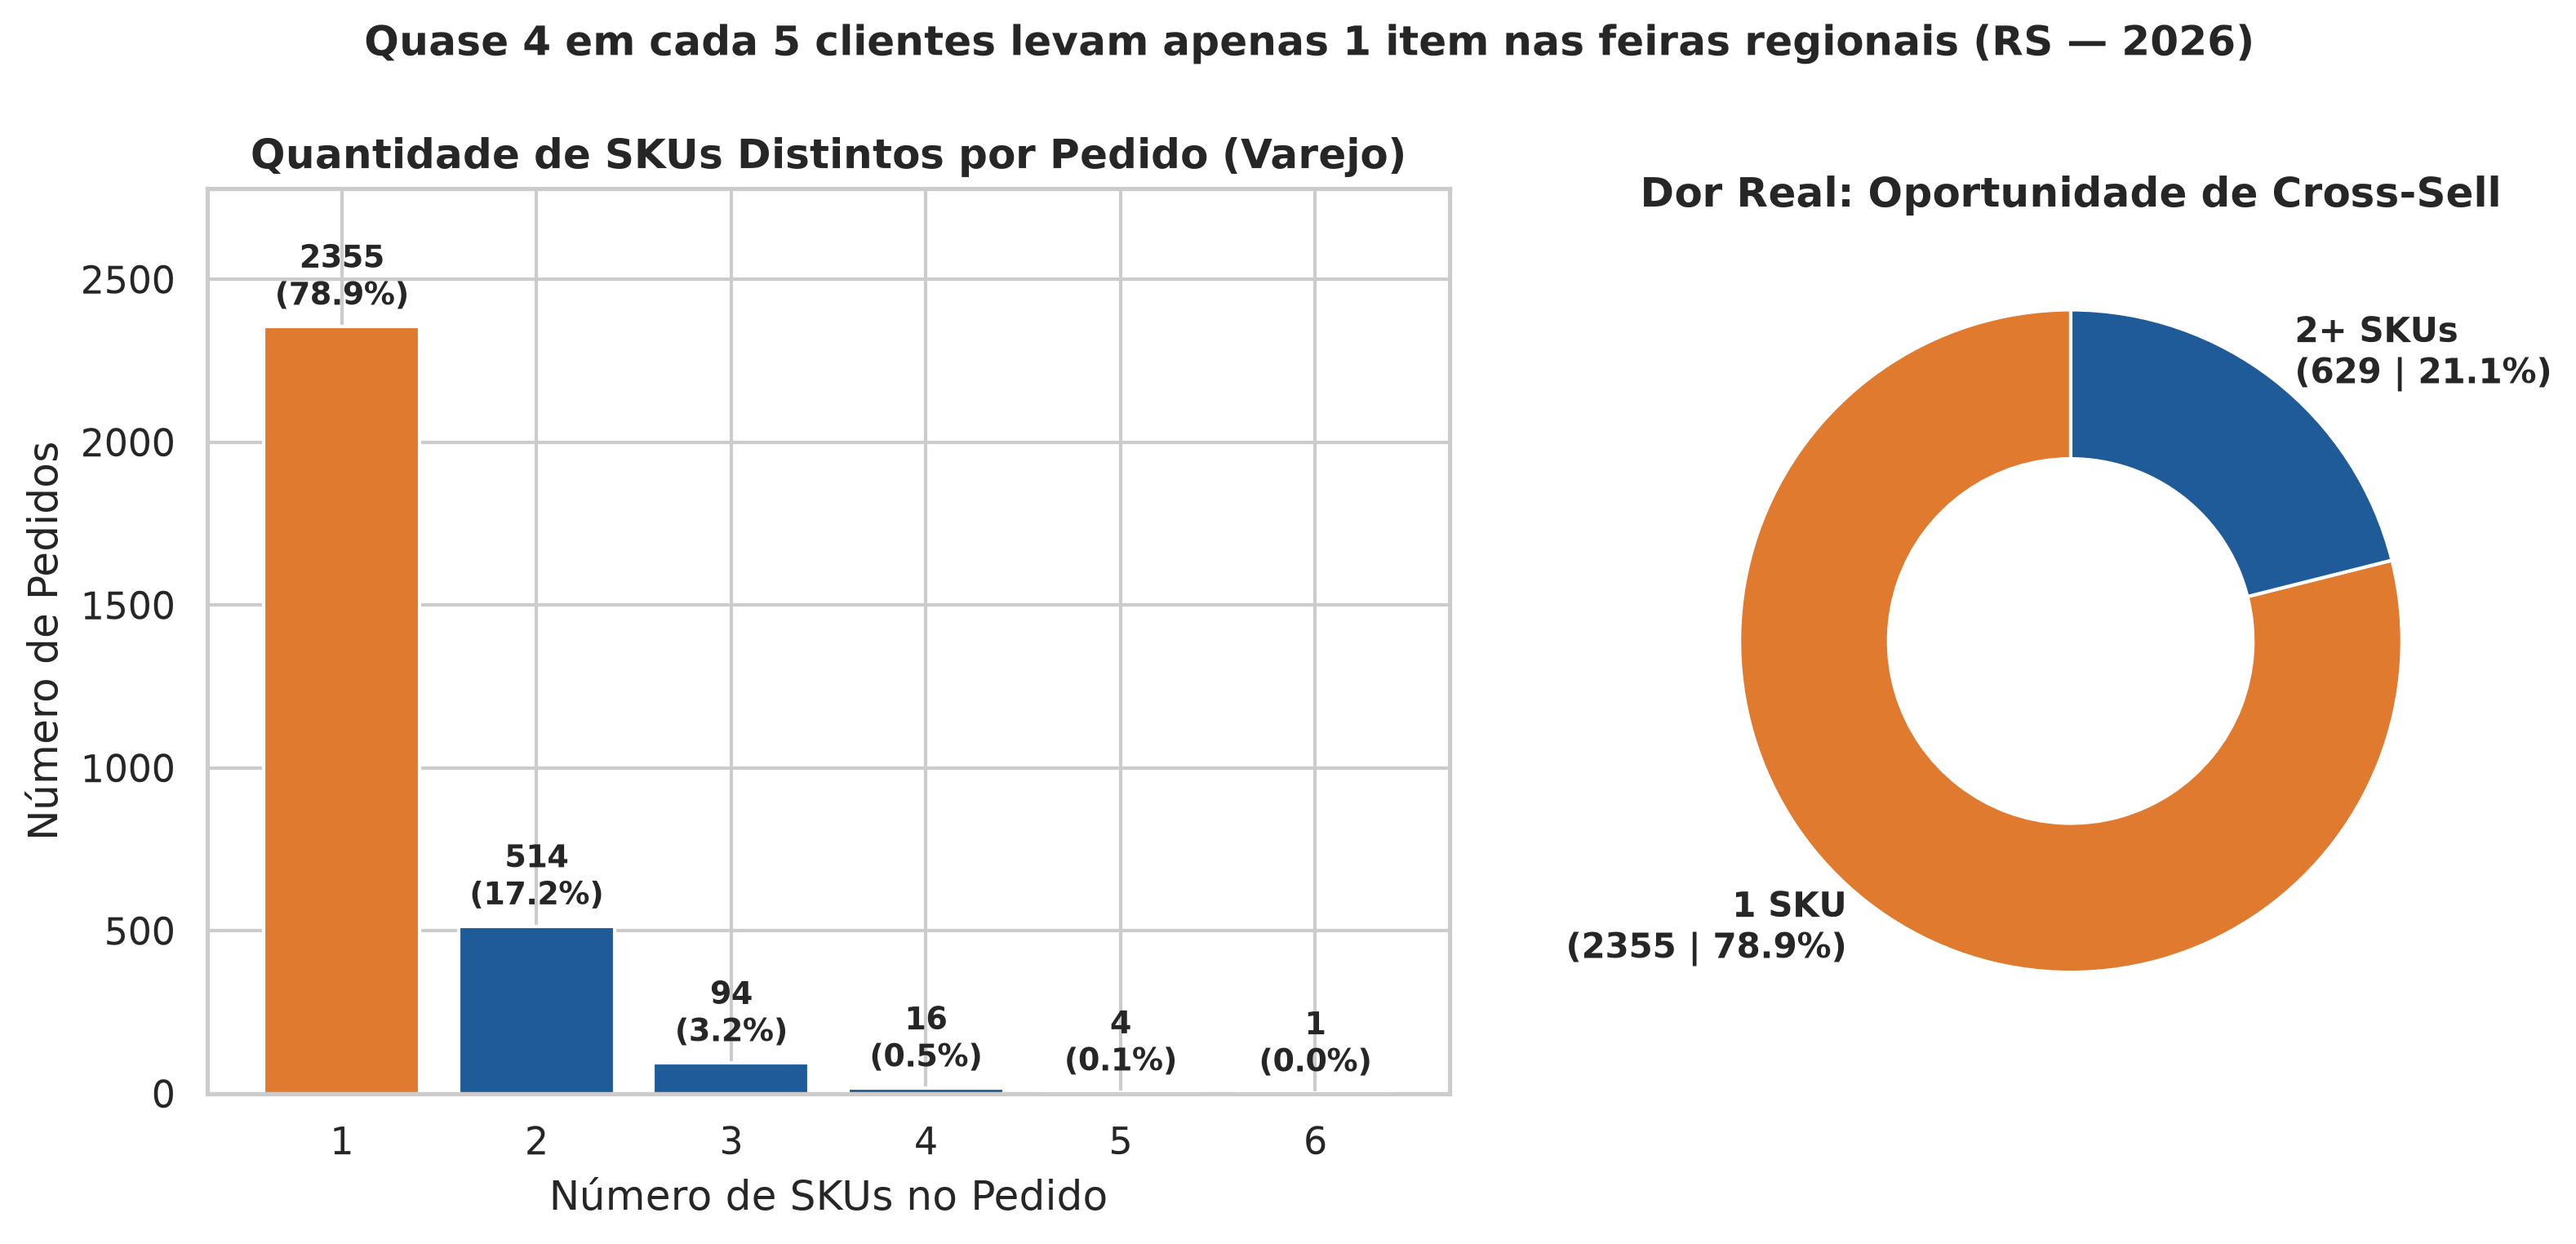

=== 02_auditoria_expodireto_antes_depois.png ===


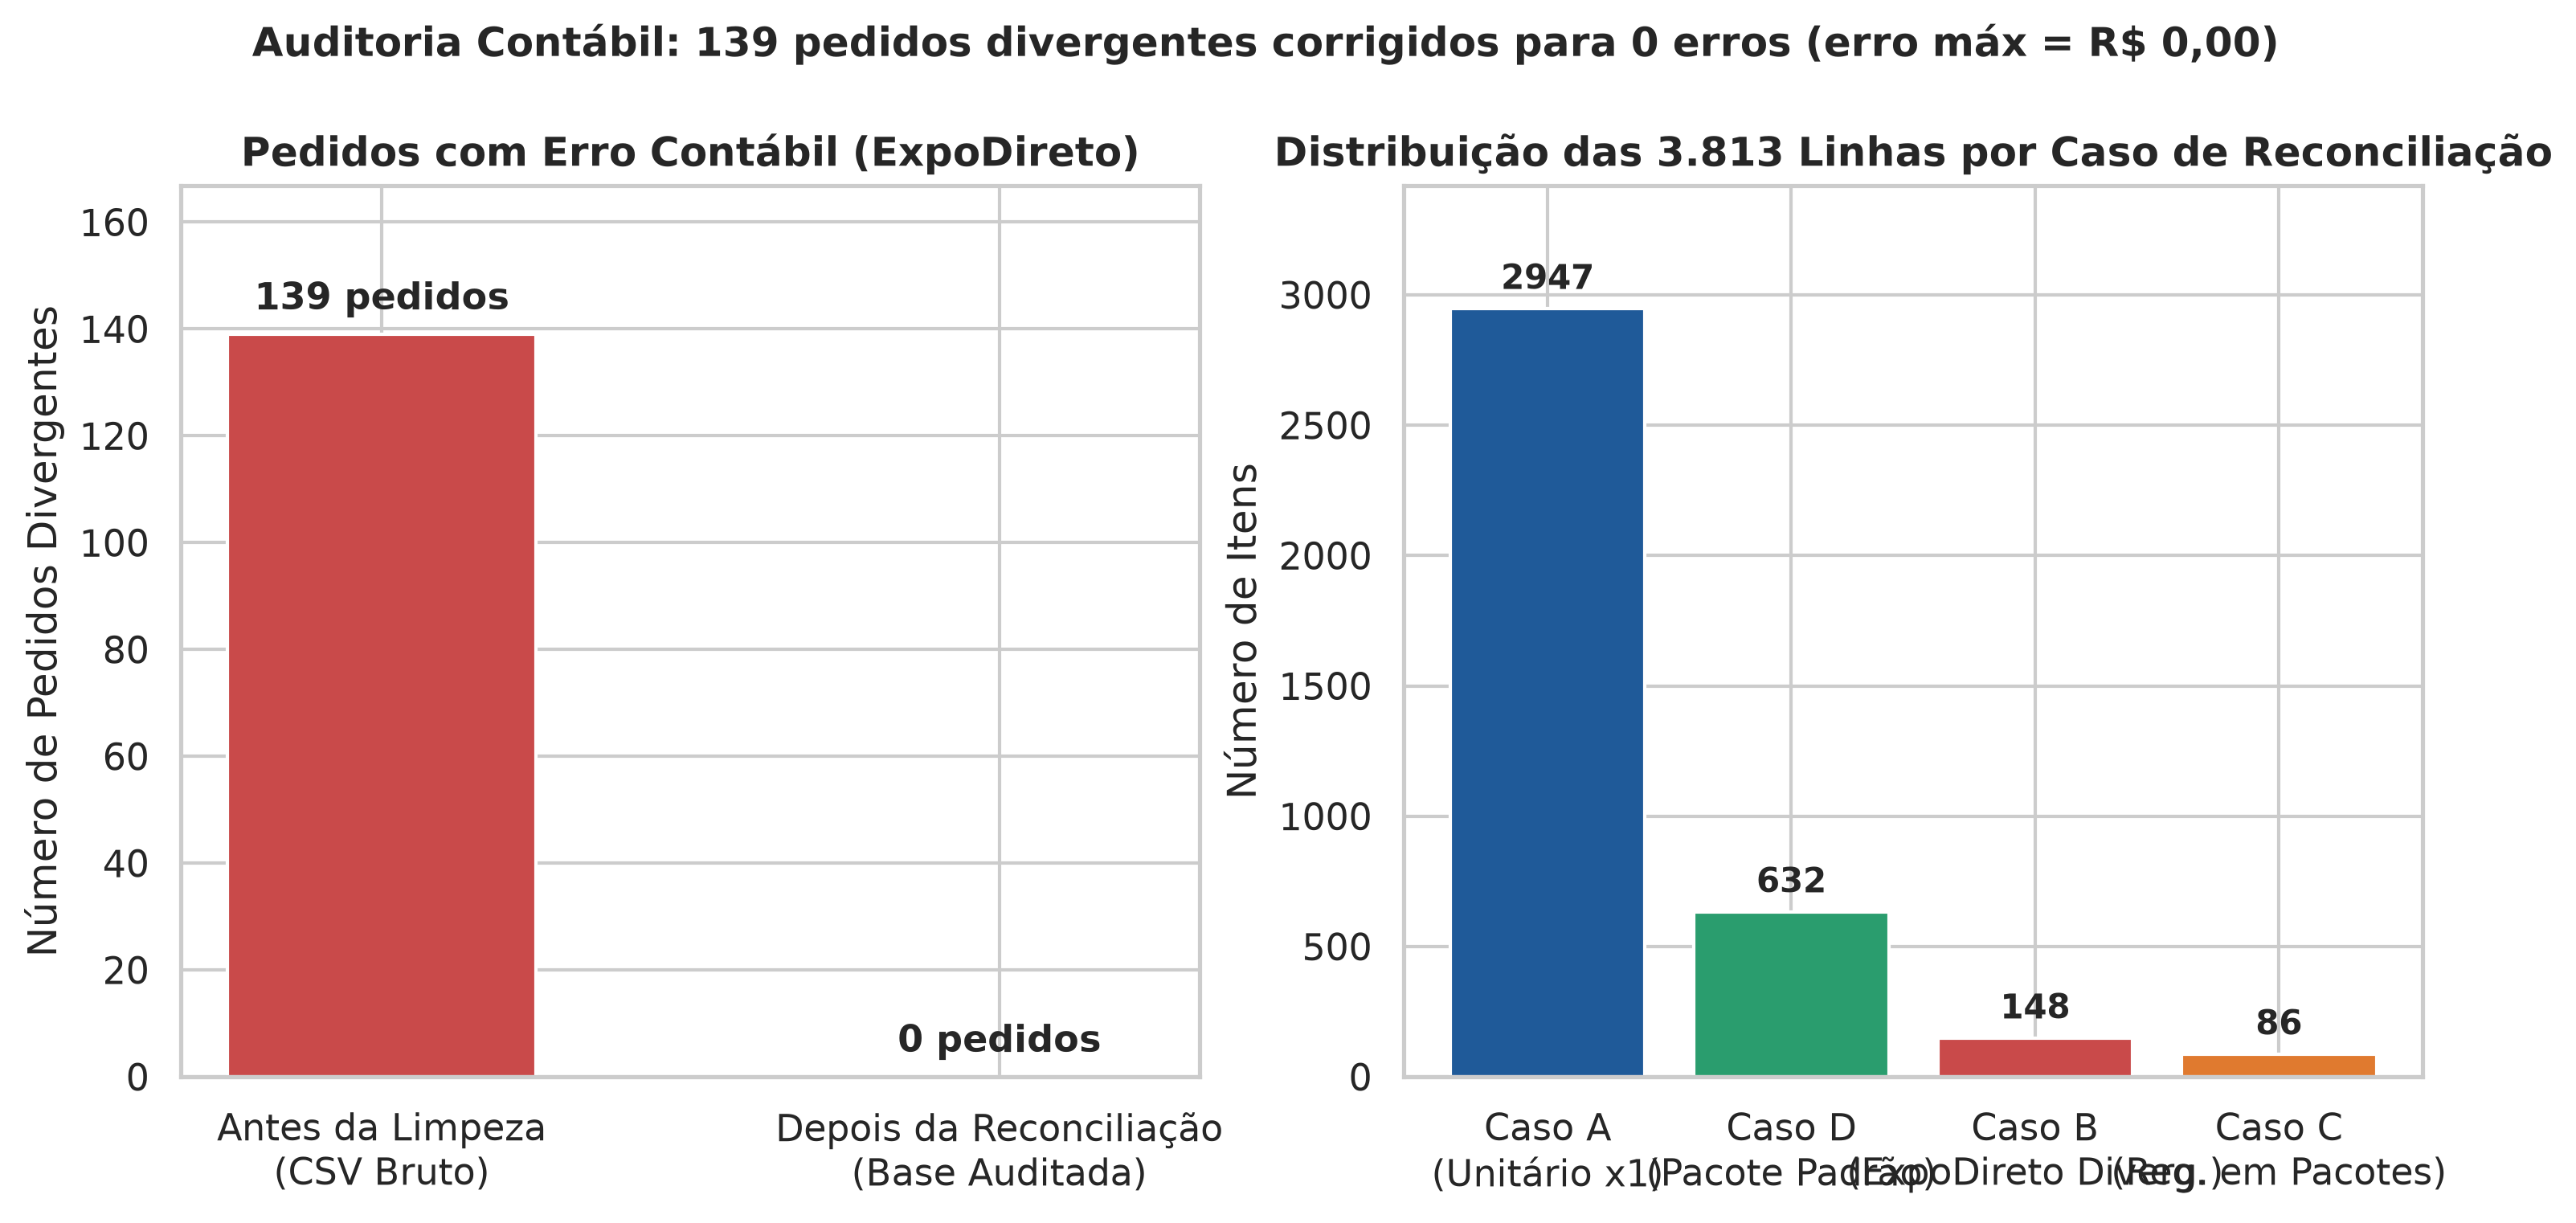

=== 03_top_produtos_e_skus.png ===


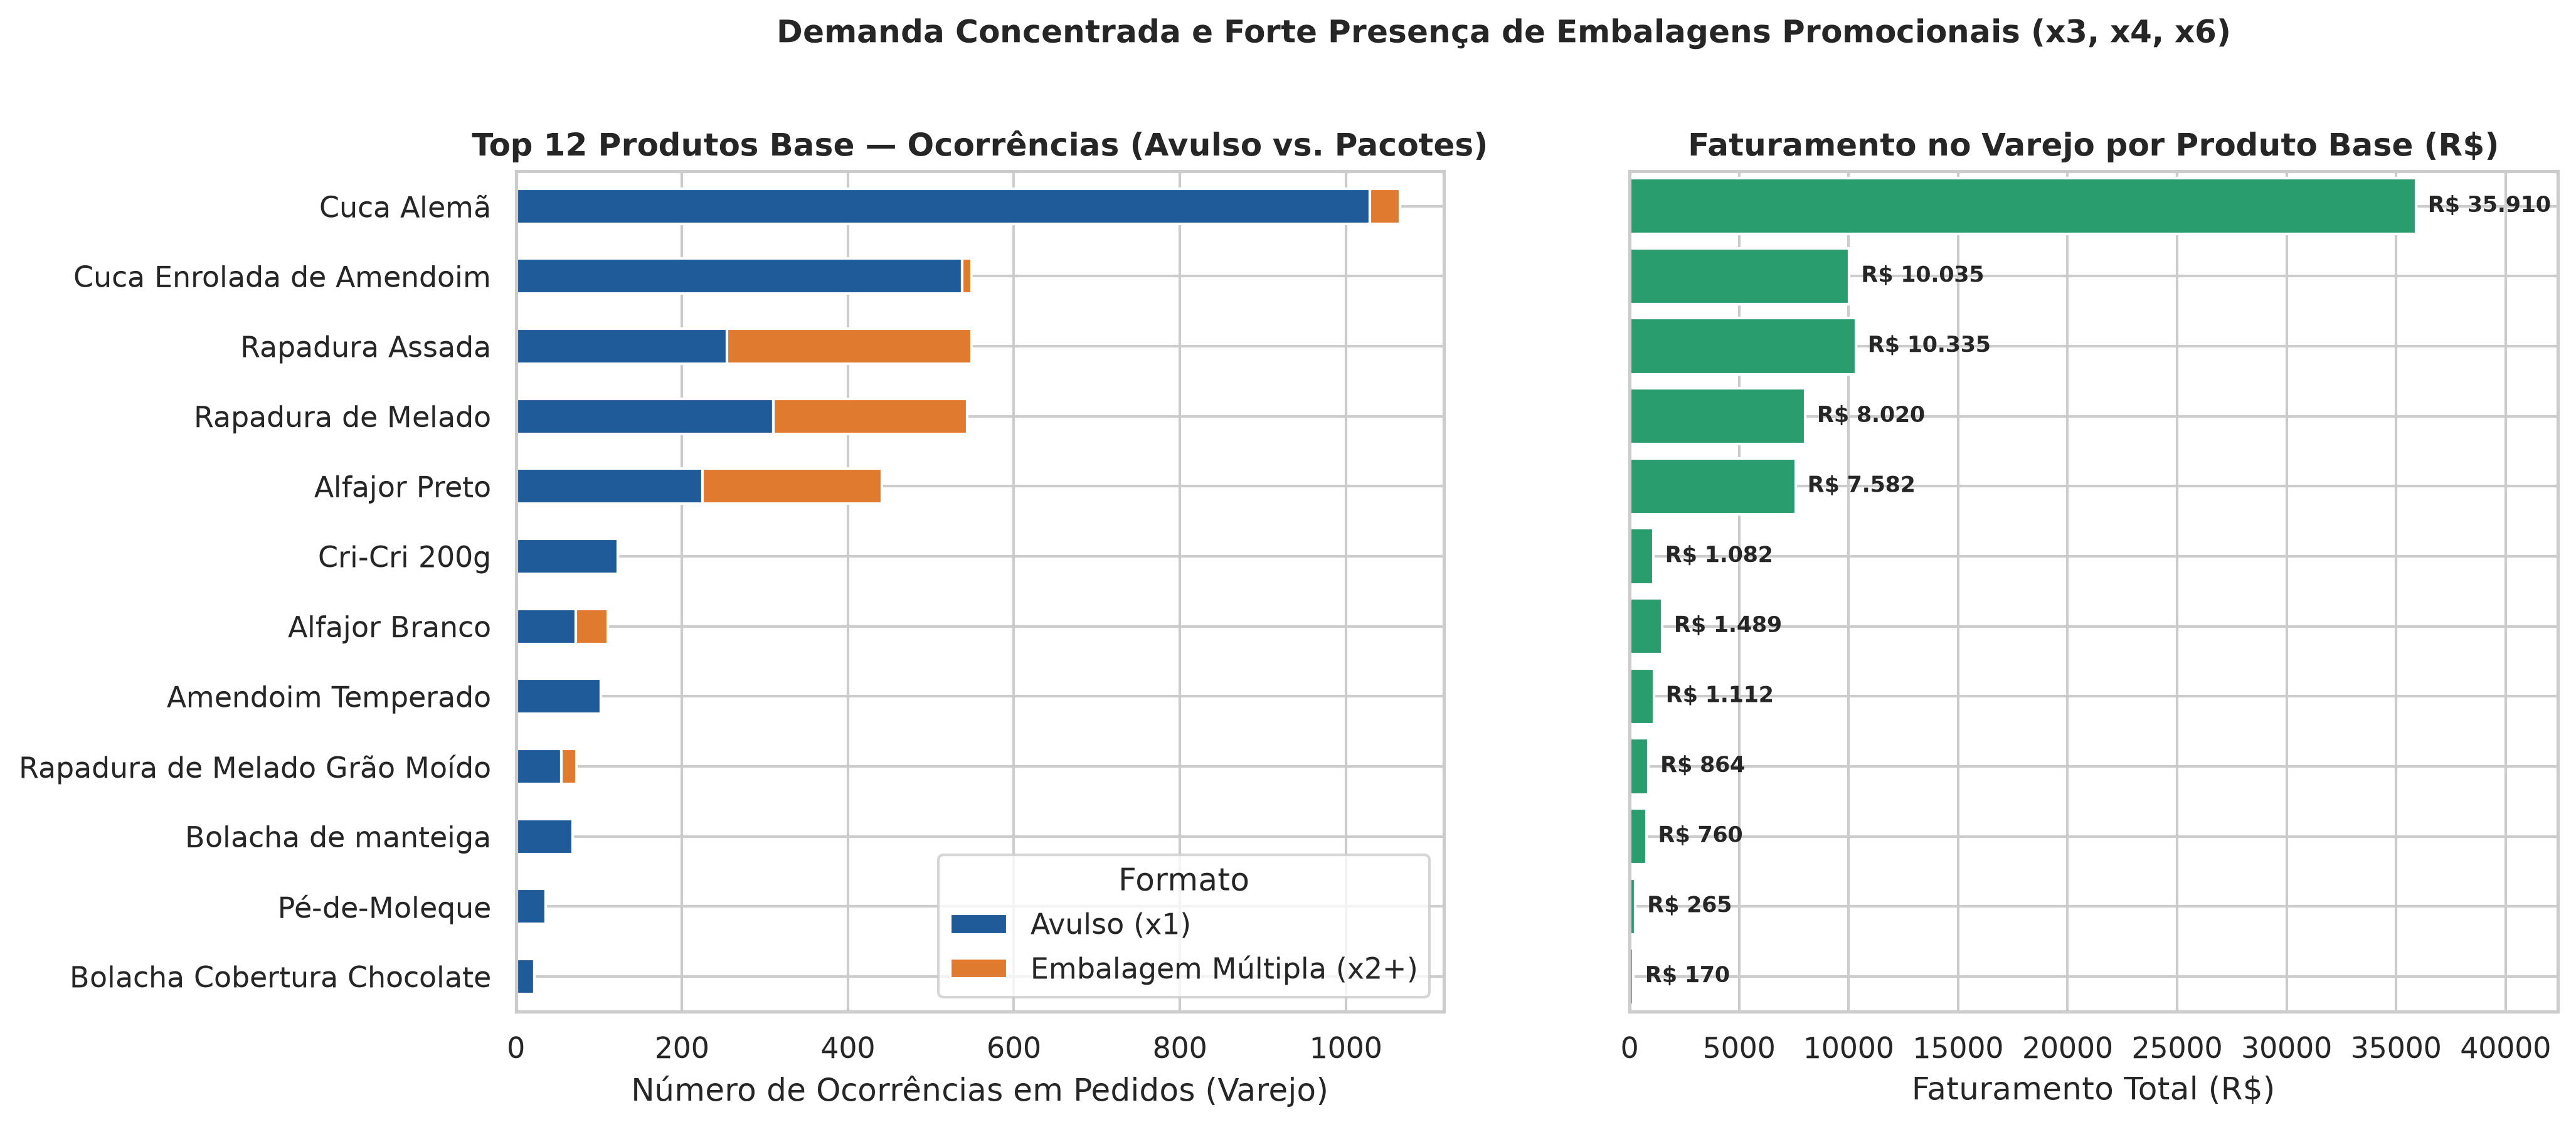

=== 04_heatmap_coocorrencia_lift.png ===


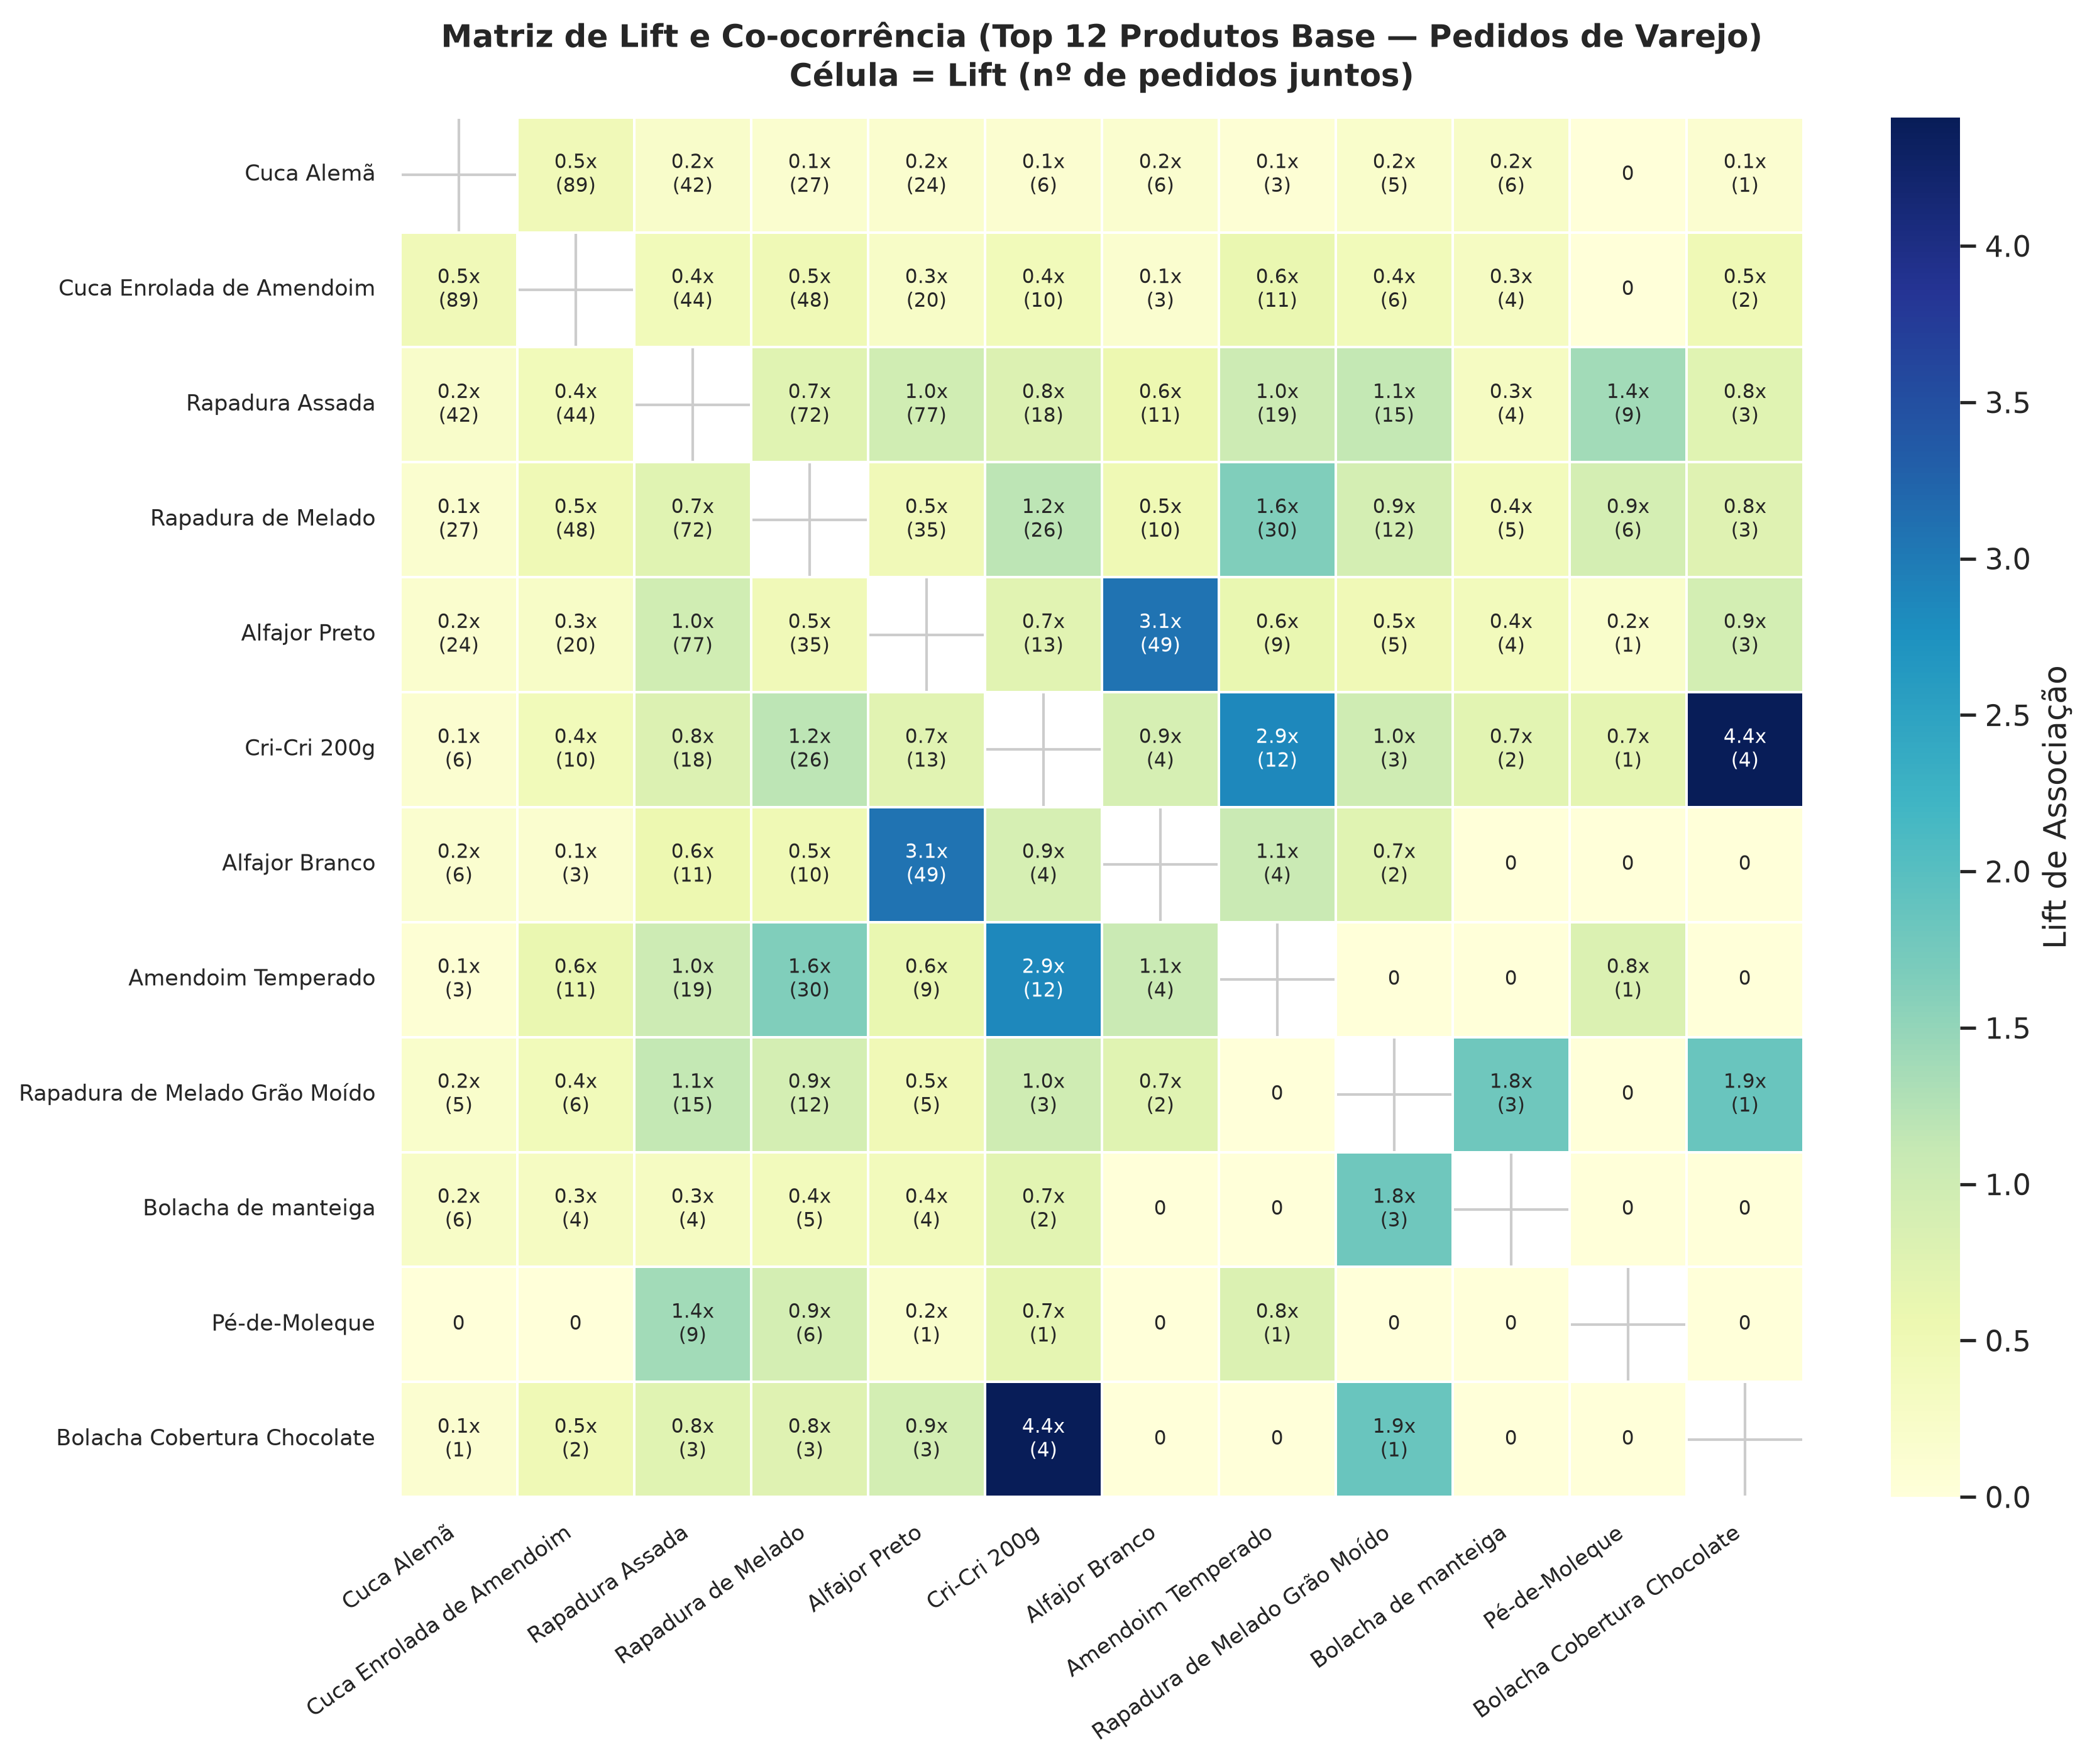

=== 05_vendas_por_feira_e_horario.png ===


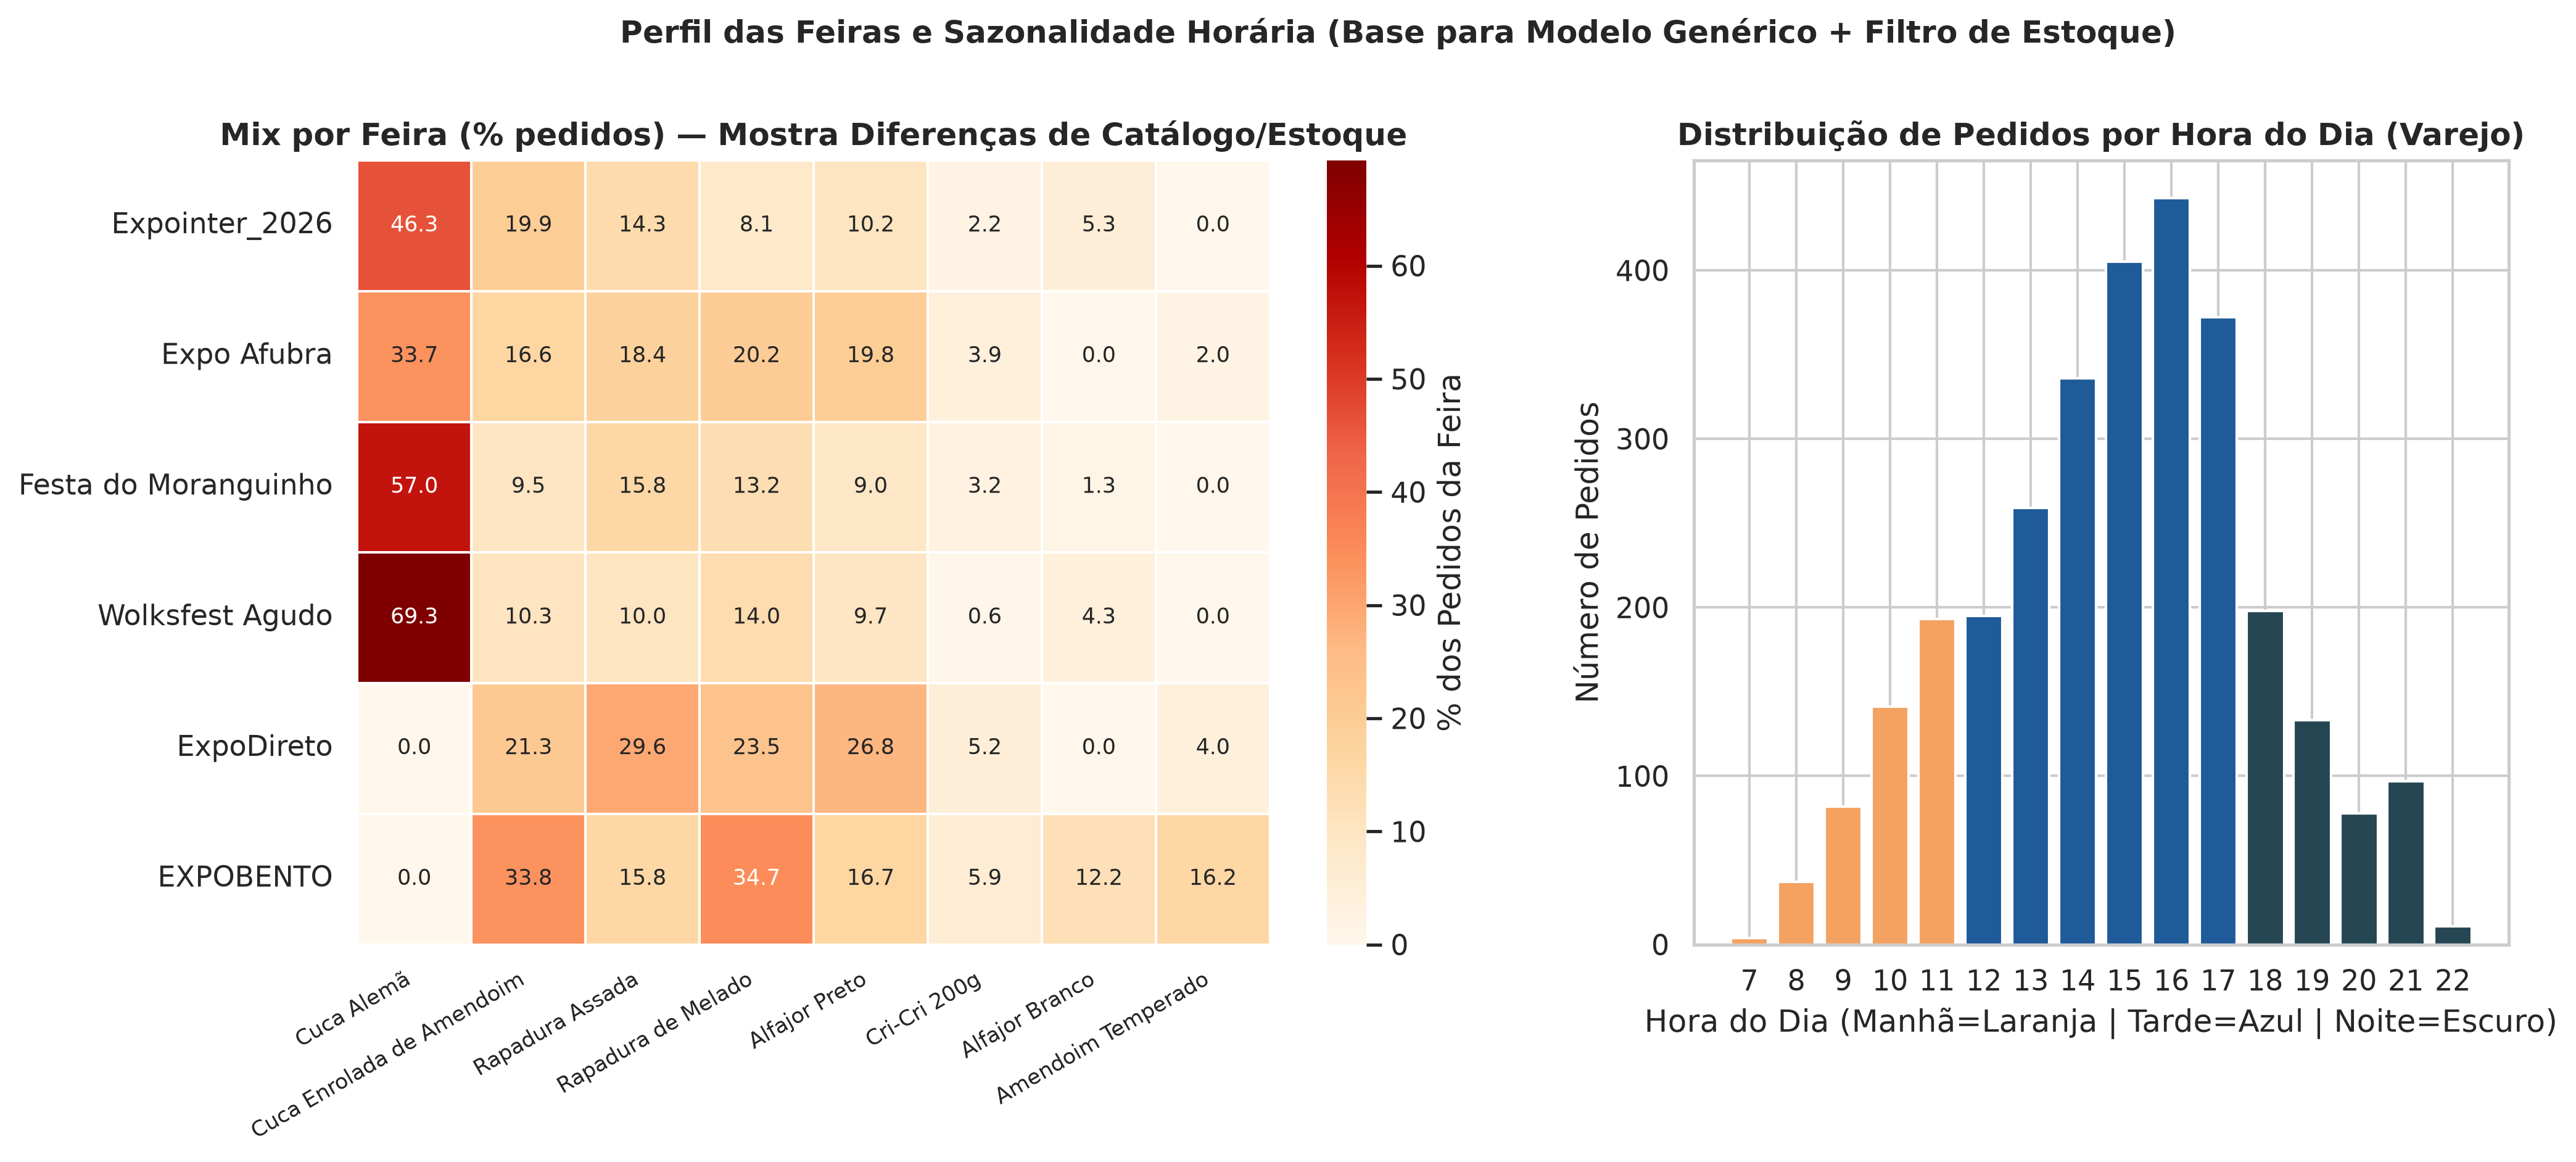

=== 06_distribuicao_qtd_pacotes_e_outliers.png ===


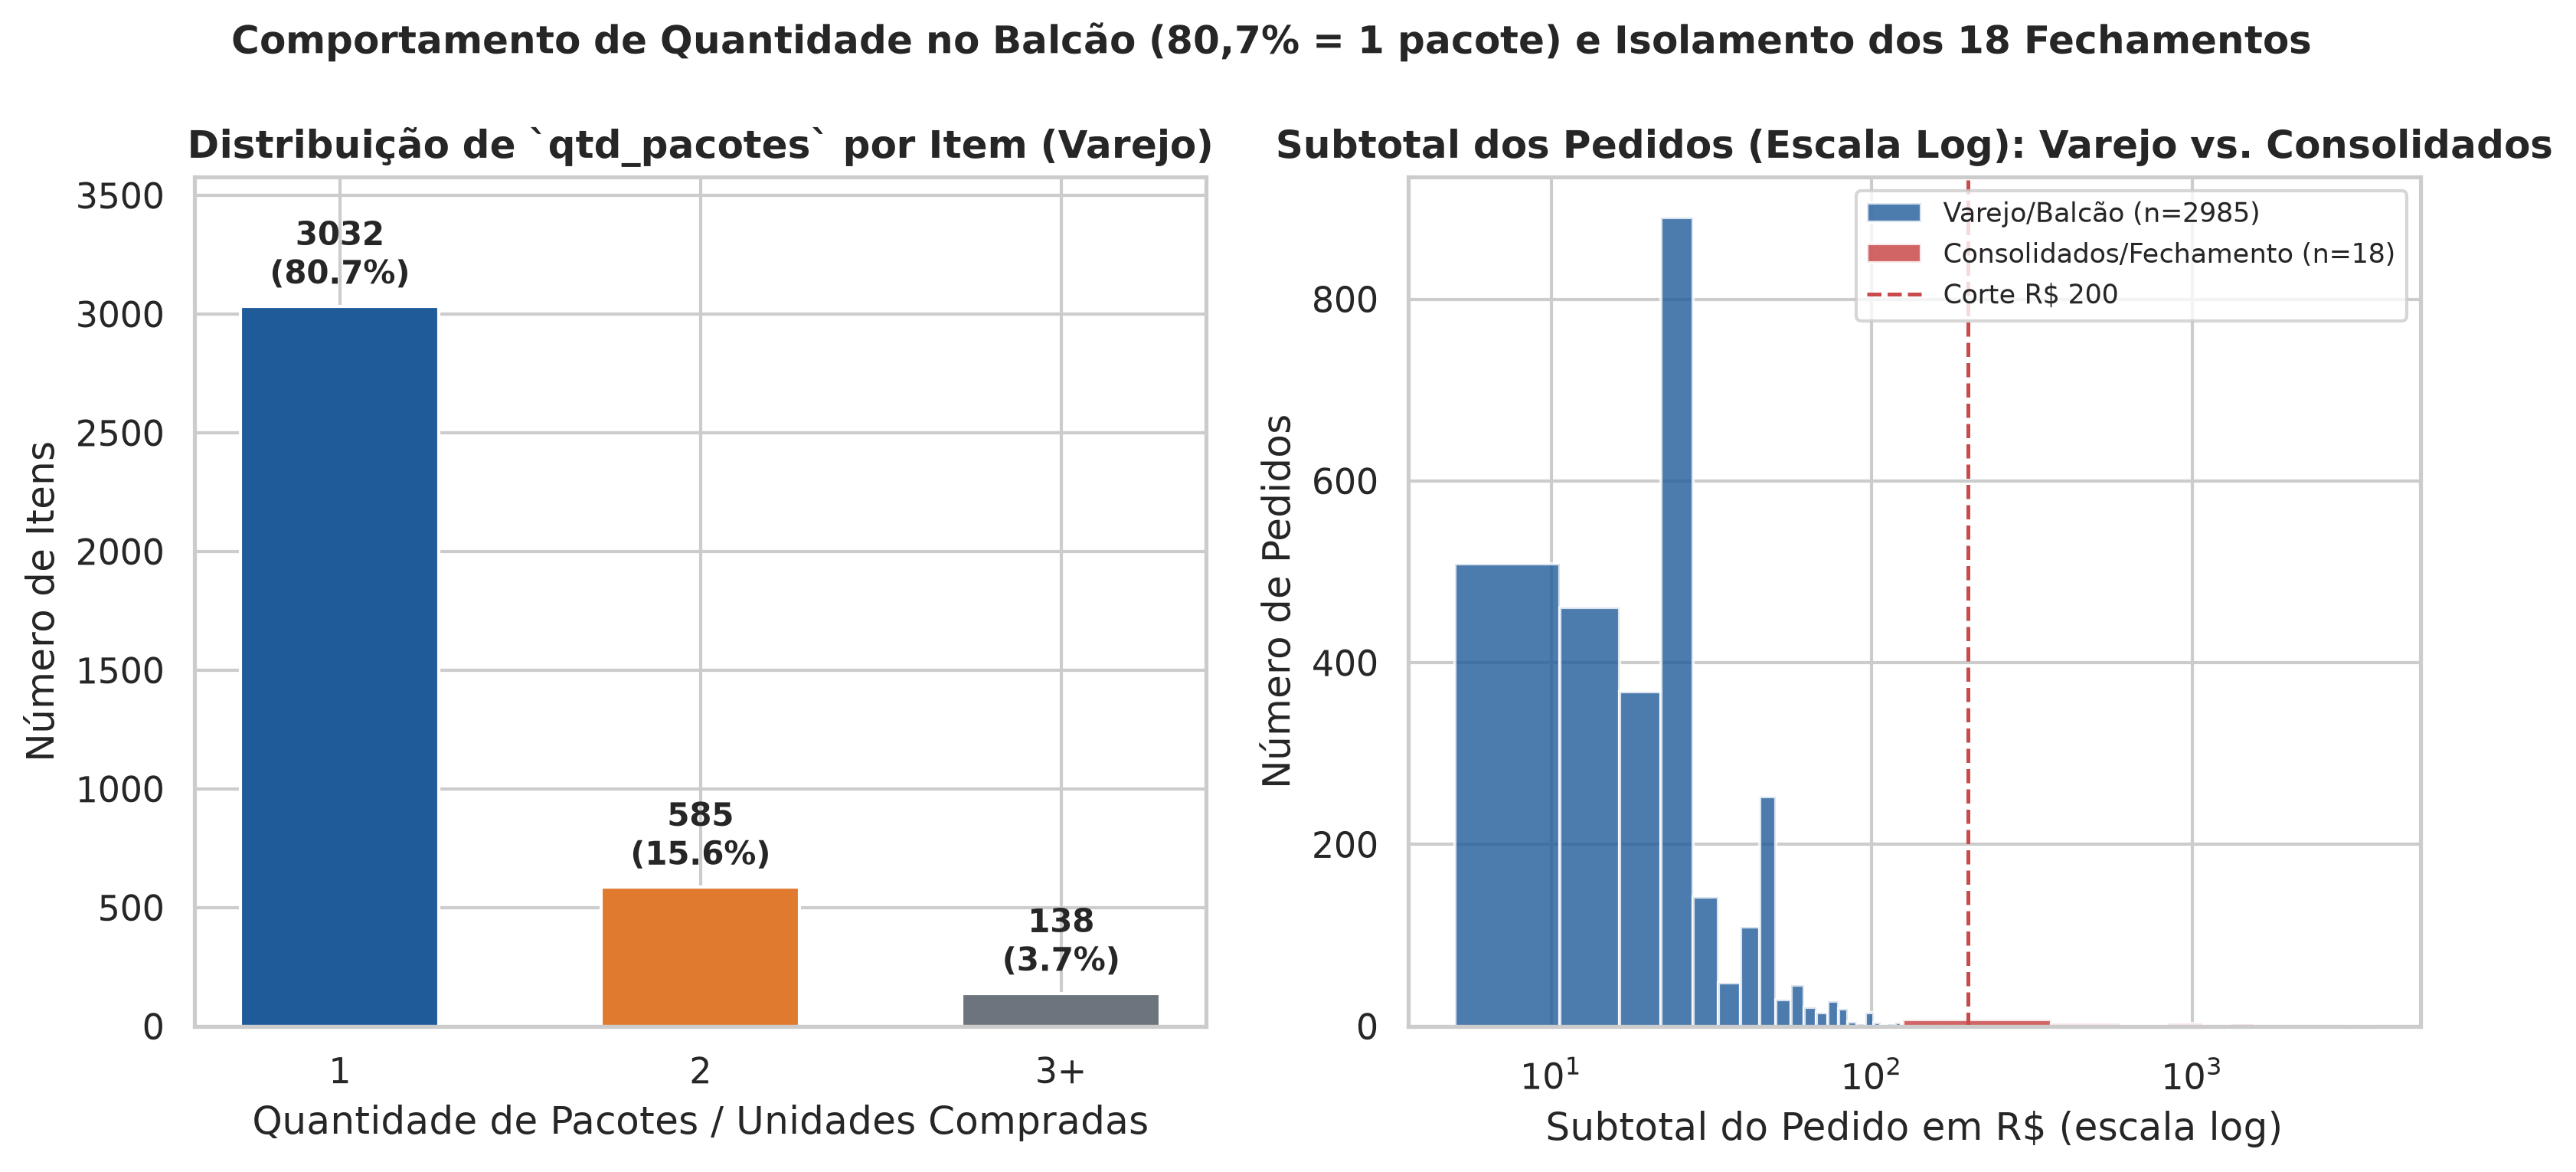

In [2]:
for fname in eda_summary['figuras_geradas']:
    print(f'=== {fname} ===')
    display(Image(filename=str(FIGURES_DIR / fname), width=850))

## Auditoria do Split 80/20 Anti-Leakage e Expansão $2^k - 2$

In [3]:
bundle = carregar_splits(SPLITS_DIR)
print(json.dumps(bundle['summary'], indent=2, ensure_ascii=False))
dev_ids = set(bundle['splits']['dev_ids'])
test_ids = set(bundle['splits']['test_ids'])
print('Interseção Dev ∩ Teste (deve ser 0):', len(dev_ids & test_ids))
print('Sobreposição entrada x alvo no Treino (deve ser 0):', int(((bundle['train']['X'][:, :34] * bundle['train']['y_sku']) > 0).sum()))

{
  "seed": 42,
  "input_dim": 99,
  "pedidos_por_split": {
    "train_ids": 2028,
    "val_ids": 359,
    "dev_ids": 2387,
    "test_ids": 597
  },
  "pedidos_multi_sku_por_split": {
    "train_ids": 427,
    "val_ids": 76,
    "dev_ids": 503,
    "test_ids": 126
  },
  "amostras_geradas": {
    "train_total": 1512,
    "train_cross_sell_subsets": 1350,
    "train_cold_start": 162,
    "val_loo": 168,
    "test_loo": 281
  }
}
Interseção Dev ∩ Teste (deve ser 0): 0
Sobreposição entrada x alvo no Treino (deve ser 0): 0
